# EDA: scraped forum posts (#31)

Explores `inputs/data/datasets.csv` (the scraped posts) before the first full run, to decide:

1. how many Problems the first full run uses (all 687 parseable, or a random subset), and
2. whether the 384 unparseable rows are scored as a separate Human group, and by which Detectors.

Not run by the pipeline. Needs only pandas and matplotlib (both on Colab). Run it from anywhere inside the repo;
on Colab, upload `datasets.csv` and `problems.csv` next to the notebook.

Every section ends with a **Read:** line to fill in after running. The decisions go in the last section.

## 1. Load

In [1]:
# %% 1. Load. Read the same way modules/problems.py does: the file has a BOM, keep every cell as text.
import ast, re, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50, "display.width", 200, "display.max_colwidth", 80)

def find(name):
    for d in [Path.cwd(), *Path.cwd().parents]:
        for p in (d / "inputs/data" / name, d / name):
            if p.exists():
                return p
    raise FileNotFoundError(f"{name} not found: run inside the repo, or upload it next to the notebook")

raw = pd.read_csv(find("datasets.csv"), dtype=str, keep_default_na=False, encoding="utf-8-sig")
problems = pd.read_csv(find("problems.csv"), dtype=str, keep_default_na=False)

d = raw.copy()
d["parses"] = d["code_parses"] == "True"
d["post_type"] = d["code_source"]          # GLOSSARY: Post type
d["code_lines"] = pd.to_numeric(d["code_lines"], errors="coerce")
d["post_score"] = pd.to_numeric(d["post_score"], errors="coerce")
d["created"] = pd.to_datetime(d["post_created_utc"], errors="coerce")
d["edited"] = pd.to_datetime(d["post_last_edited_utc"], errors="coerce")
d["year"] = d["created"].dt.year
d["code_chars"] = d["code"].str.len()
d["group"] = np.where(d["parses"], "parses", "unparseable")

# Self-check against the numbers in #29 / #31.
assert len(d) == 1071, len(d)
assert d["parses"].sum() == 687 and (~d["parses"]).sum() == 384, d["parses"].value_counts()
assert len(problems) == 687, len(problems)
assert d["sample_id"].is_unique
print(sys.version)
print(d.shape)
d.head(3)

3.13.15 (main, Aug 14 2026, 15:24:40) [Clang 22.1.3 ]
(1071, 26)


,sample_id,site,code_source,question_id,answer_id,question_title,question_text,code,code_lines,code_parses,post_created_utc,post_last_edited_utc,post_score,tags,author,author_link,link,question_link,license,parses,post_type,created,edited,year,code_chars,group
0,H0001,stackoverflow,question,32538758,,NameError: name 'get_ipython' is not defined,I am working on Caffe framework and using PyCaffe interface. I am using a Py...,import numpy as np\nimport matplotlib.pyplot as plt\n\nget_ipython().magic(u...,19,True,2015-09-12 12:25:27,2015-09-12 12:31:54,69.0,python;ipython;caffe;pycaffe,dyno8426,https://stackoverflow.com/users/2452617/dyno8426,https://stackoverflow.com/questions/32538758/nameerror-name-get-ipython-is-n...,https://stackoverflow.com/questions/32538758/nameerror-name-get-ipython-is-n...,CC BY-SA 3.0,True,question,2015-09-12 12:25:27,2015-09-12 12:31:54,2015,403,parses
1,H0002,stackoverflow,question,32401493,,How to create/customize your own scorer function in scikit-learn?,I am using Support Vector Regression as an estimator in GridSearchCV . But I...,"def my_custom_loss_func(X_train_scaled, Y_train_scaled):\n error, M = 0, ...",12,True,2015-09-04 15:20:08,2016-04-15 00:16:18,62.0,python;scikit-learn,daniel2014,https://stackoverflow.com/users/4371803/daniel2014,https://stackoverflow.com/questions/32401493/how-to-create-customize-your-ow...,https://stackoverflow.com/questions/32401493/how-to-create-customize-your-ow...,CC BY-SA 3.0,True,question,2015-09-04 15:20:08,2016-04-15 00:16:18,2015,721,parses
2,H0003,stackoverflow,question,45847313,,What does 'weight' do in tkinter?,I've been searching different websites trying to find out what weight does i...,try:\n import tkinter\nexcept ImportError: # python 2\n import Tkinte...,33,True,2017-08-23 18:48:29,2017-12-23 16:45:41,63.0,python;tkinter,Fred,https://stackoverflow.com/users/6713072/fred,https://stackoverflow.com/questions/45847313/what-does-weight-do-in-tkinter,https://stackoverflow.com/questions/45847313/what-does-weight-do-in-tkinter,CC BY-SA 3.0,True,question,2017-08-23 18:48:29,2017-12-23 16:45:41,2017,928,parses


In [2]:
# %% 1b. Empty cells per column (empty string = missing in this file).
(raw == "").sum().to_frame("empty").assign(share=lambda t: (t["empty"] / len(raw)).round(3)).T

,sample_id,site,code_source,question_id,answer_id,question_title,question_text,code,code_lines,code_parses,post_created_utc,post_last_edited_utc,post_score,tags,author,author_link,link,question_link,license
empty,0.0,0.0,0.0,0.0,466.000,0.0,0.0,0.0,0.0,0.0,0.0,282.000,90.000,0.0,0.0,15.000,0.0,0.0,10.000
share,0.0,0.0,0.0,0.0,0.435,0.0,0.0,0.0,0.0,0.0,0.0,0.263,0.084,0.0,0.0,0.014,0.0,0.0,0.009


**Read:** which columns have gaps that matter (dates, score, question_text)?

## 2. Counts by site, Post type, parses

group                    parses  unparseable   All  parse_rate
site          post_type                                       
codereview    answer        147           59   206       0.714
              question      145           61   206       0.704
github        answer         48           42    90       0.533
stackoverflow answer        200          109   309       0.647
              question      147          113   260       0.565
All                         687          384  1071       0.641

Main set (parses) share by site x Post type:


post_type,answer,question,All
site,,,
codereview,147,145,292
github,48,0,48
stackoverflow,200,147,347
All,395,292,687


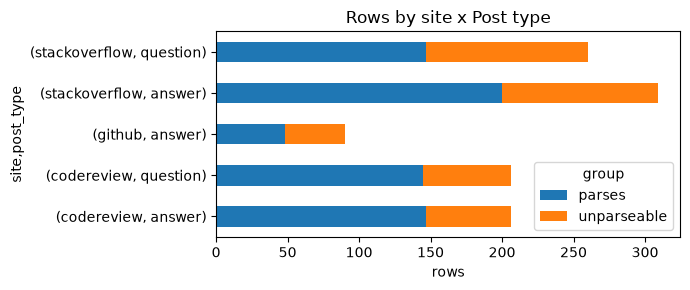

In [3]:
# %% 2. Counts. Parse rate per cell shows which source the parse filter thins out.
counts = pd.crosstab([d["site"], d["post_type"]], d["group"], margins=True)
counts["parse_rate"] = (counts["parses"] / counts["All"]).round(3)
display(counts)

kept = d[d["parses"]]
print("Main set (parses) share by site x Post type:")
display(pd.crosstab(kept["site"], kept["post_type"], margins=True, normalize=False))

fig, ax = plt.subplots(figsize=(7, 3))
pd.crosstab([d["site"], d["post_type"]], d["group"]).plot.barh(stacked=True, ax=ax)
ax.set_xlabel("rows"); ax.set_title("Rows by site x Post type"); plt.tight_layout(); plt.show()

**Read:** is any site or Post type so small (or so dominant) in the main set that per-split Results
(Human split) would be noise?

## 3. Re-check `code_parses` and why code fails

`code_parses` came with the file. Re-parse here with `ast.parse` on this Python (Colab is 3.13), and bucket the
failures. The bucket rules are rough heuristics: read the examples. Python 3.14 accepts `except A, B:`
(PEP 758), so Python 2 code with `except E, e:` parses there and the counts depend on the version.

In [4]:
# %% 3. Re-parse and bucket the failures.
def parse_error(src):
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")   # invalid escape sequences etc.
            ast.parse(src)
        return None
    except SyntaxError as e:          # IndentationError and TabError are SyntaxError subclasses
        return f"{type(e).__name__}: {e.msg}"
    except (ValueError, RecursionError, MemoryError) as e:   # null bytes, deep nesting
        return f"{type(e).__name__}"

d["error"] = d["code"].map(parse_error)
d["parses_here"] = d["error"].isna()
dis = d[d["parses"] != d["parses_here"]]
print(f"Python {sys.version.split()[0]}: {len(dis)} rows disagree with code_parses")
display(dis[["sample_id", "site", "post_type", "parses", "error"]].head(20))

PY2_PRINT = re.compile(r"^\s*print\s+[^\s(=.,)\]]", re.M)       # print "x" / print x
PY2_EXCEPT = re.compile(r"^\s*except\s+[\w.]+\s*,\s*\w+\s*:", re.M)  # except E, e:
PROMPT = re.compile(r"^\s*(>>>|In \[\d+\]:|\$ )", re.M)            # pasted REPL/shell session
ELLIPSIS = re.compile(r"^\s*(\.\.\.|…)\s*$", re.M)                 # elided lines

def bucket(row):
    if row["parses_here"]:
        return "parses on this Python"
    c, e = row["code"], row["error"] or ""
    if PY2_PRINT.search(c) or PY2_EXCEPT.search(c) or "Missing parentheses in call to 'print'" in e:
        return "python2"
    if PROMPT.search(c):
        return "pasted REPL/shell"
    if e.startswith(("IndentationError", "TabError")):
        return "indentation"
    if ELLIPSIS.search(c):
        return "elided lines (...)"
    if "never closed" in e or "unexpected EOF" in e or "was not closed" in e:
        return "cut off / unclosed"
    return "other"

d["fail_bucket"] = d.apply(bucket, axis=1)
u = d[~d["parses"]]
display(pd.crosstab(u["fail_bucket"], u["site"], margins=True))
print("Most common error messages (unparseable rows):")
display(u["error"].str.replace(r"\(.*?\)|'.*?'", "…", regex=True).value_counts().head(15))

Python 3.13.15: 8 rows disagree with code_parses


,sample_id,site,post_type,parses,error
22,H0023,stackoverflow,question,False,NaN
115,H0116,stackoverflow,answer,False,NaN
298,N0009,stackoverflow,question,False,NaN
395,N0106,stackoverflow,question,False,NaN
433,N0144,stackoverflow,question,False,NaN
719,N0430,stackoverflow,answer,False,NaN
768,N0479,codereview,question,False,NaN
890,N0601,codereview,question,False,NaN


site,codereview,github,stackoverflow,All
fail_bucket,,,,
cut off / unclosed,3,0,1,4
elided lines (...),5,0,3,8
indentation,18,0,22,40
other,14,2,78,94
parses on this Python,2,0,6,8
pasted REPL/shell,4,0,14,18
python2,74,40,98,212
All,120,42,222,384


Most common error messages (unparseable rows):


error
SyntaxError: Missing parentheses in call to …. Did you mean print…?                                              189
SyntaxError: invalid syntax                                                                                       81
IndentationError: unexpected indent                                                                               25
SyntaxError: invalid decimal literal                                                                               9
SyntaxError: multiple exception types must be parenthesized                                                        8
SyntaxError: invalid syntax. Perhaps you forgot a comma?                                                           7
SyntaxError: expected …                                                                                            7
SyntaxError: unmatched …                                                                                           6
SyntaxError: unterminated string literal …                

In [5]:
# %% 3b. One example per bucket (first 12 lines).
for b, g in u.groupby("fail_bucket"):
    r = g.iloc[0]
    print(f"=== {b}  ({len(g)} rows)  {r['sample_id']}  {r['error']}")
    print("\n".join(r["code"].splitlines()[:12]), "\n")

=== cut off / unclosed  (4 rows)  N0385  SyntaxError: '(' was never closed
import pandas as pd
import numpy as np
from turbodbc import connect, make_options
from io import StringIO

test_data = '''id,transaction_dt,units,measures
               1,2018-01-01,4,30.5
               1,2018-01-03,4,26.3
               2,2018-01-01,3,12.7
               2,2018-01-03,3,8.8'''

df_test = pd.read_csv(StringIO(test_data), sep=',') 

=== elided lines (...)  (8 rows)  H0195  SyntaxError: invalid syntax
with open('input') as f:
    parseFile(f)

def parseFile(...):
    ...
    for pair in pairs(expr_input): parsePair(pair)
    ...

def parsePair(...):
    ...
    for i, s in enumerate(expression): addExpressionToSummation(i, s)
    ... 

=== indentation  (40 rows)  H0006  IndentationError: unexpected indent
df = pd.DataFrame({"A" : [6, 2, 10, -5, 3],
                   "B" : [2, 5, 3, 2, 6],
                   "C" : [-5, 2, 1, 8, 2]})
limits_dic = {"A" : 0, "B" : 2, "C" : -1}
def filtering(df, limi

**Read:** do the disagreements (if any) change the 687 / 384 split? How much of the unparseable group is
Python 2 (fixable in principle, old) vs pasted output or fragments (not really code)?

## 4. Code length

LLM Generators write complete solutions. If Human code is mostly short fragments (often the case for
`question` posts), length alone could separate the labels, and a Detector would look better than it is.

code_lines by site x Post type x group:


count  mean   std   min   10%   25%   50%   75%   90%    max
group       site          post_type                                                              
parses      codereview    answer     147.0  29.1  20.7  10.0  12.0  15.0  22.0  34.0  57.4  105.0
                          question   145.0  47.7  28.0  10.0  15.0  26.0  38.0  63.0  93.6  126.0
            github        answer      48.0  41.3  22.0  11.0  15.7  22.8  42.5  53.0  62.6  121.0
            stackoverflow answer     200.0  23.0  14.2  10.0  12.0  14.0  18.0  27.0  39.0  107.0
                          question   147.0  22.6  14.0  10.0  13.0  15.0  18.0  26.0  38.8   96.0
unparseable codereview    answer      59.0  28.7  19.9  10.0  12.0  15.0  23.0  31.0  64.8   91.0
                          question    61.0  53.2  29.5  12.0  18.0  33.0  47.0  75.0  94.0  124.0
            github        answer      42.0  34.1  16.8   9.0  18.0  20.2  31.0  42.2  55.5   89.0
            stackoverflow answer     109.0  25.9  16.2  10.0  12.0  15.0  20.0  33.0  47.2   89.0
                          question   113.0  26.4  17.1  10.0  12.0  14.0  22.0  33.0  46.4  119.0

main set with <= 1 lines: 0
main set with <= 2 lines: 0
main set with <= 3 lines: 0
main set with <= 5 lines: 0
longest main-set snippets (lines): [126, 121, 115, 112, 109]


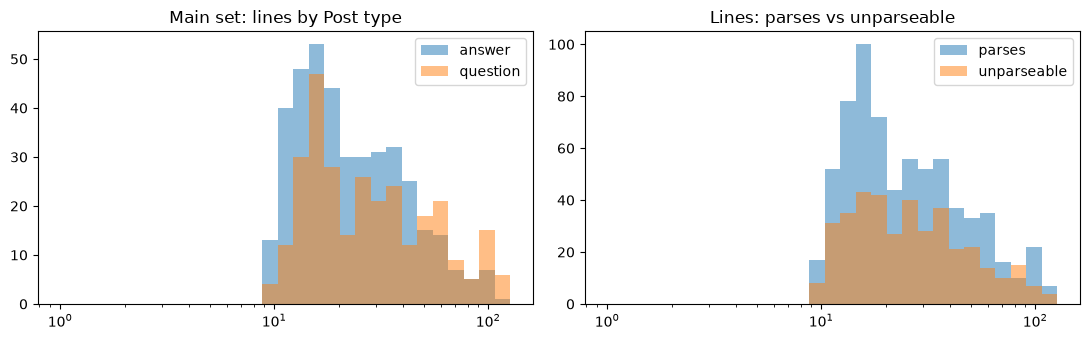

In [6]:
# %% 4. Length by group.
print("code_lines by site x Post type x group:")
display(d.groupby(["group", "site", "post_type"])["code_lines"]
          .describe(percentiles=[.1, .25, .5, .75, .9]).round(1))

assert (d["code_lines"] == d["code"].str.count("\n") + 1).mean() > 0.9, "code_lines is not a line count?"
for n in (1, 2, 3, 5):
    print(f"main set with <= {n} lines: {(kept['code_lines'] <= n).sum()}")
print("longest main-set snippets (lines):", kept["code_lines"].nlargest(5).tolist())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
bins = np.logspace(0, np.log10(d["code_lines"].max() + 1), 30)
for (pt, g) in kept.groupby("post_type"):
    axes[0].hist(g["code_lines"], bins=bins, alpha=.5, label=pt)
axes[0].set_xscale("log"); axes[0].set_title("Main set: lines by Post type"); axes[0].legend()
for (gr, g) in d.groupby("group"):
    axes[1].hist(g["code_lines"], bins=bins, alpha=.5, label=gr)
axes[1].set_xscale("log"); axes[1].set_title("Lines: parses vs unparseable"); axes[1].legend()
plt.tight_layout(); plt.show()

In [7]:
# %% 4b. The shortest main-set snippets: are they usable Human Samples?
for _, r in kept.nsmallest(8, "code_lines").iterrows():
    print(f"--- {r['sample_id']} {r['site']}/{r['post_type']} ({r['code_lines']} lines)")
    print(r["code"][:300])

--- H0112 stackoverflow/answer (10 lines)
def slugify(value):
    """
    Converts to lowercase, removes non-word characters (alphanumerics and
    underscores) and converts spaces to hyphens. Also strips leading and
    trailing whitespace.
    """
    value = unicodedata.normalize('NFKD', value).encode('ascii', 'ignore').decode('ascii')
 
--- H0191 codereview/answer (10 lines)
import re
def get_input():
    regex = "(\d+)(?:\.\.(\d+)(?:\'(\d*))?)?"
    for match in re.findall(regex, input("> ")):
        match = [int(i) for i in match if i]
        if len(match) == 1:
            yield match[0]
        else:
            for j in range(*match):
                yield j
--- N0021 stackoverflow/question (10 lines)
fig , ( (ax1,ax2) , (ax3,ax4)) = plt.subplots(2, 2,sharex = True,sharey=True)
z1_plot = ax1.scatter(x,y,c = z1,vmin=0.0,vmax=0.4)
plt.colorbar(z1_plot,cax=ax1)
z2_plot = ax2.scatter(x,y,c = z2,vmin=0.0,vmax=40)
plt.colorbar(z1_plot,cax=ax2)
z3_plot = ax3.scatter(x,y,c = z3,vmin

**Read:** median length per Post type; how many tiny snippets (<= 2 lines); should a minimum length be a
filter rule (that would be a change to `modules/problems.py`, a separate ticket)?

## 5. Post year and LLM contamination

ChatGPT came out on 2022-11-30. Code posted or edited after that may already be LLM-written, which would put
LLM code under the Human label.

group     parses                      unparseable                        All
site  codereview github stackoverflow  codereview github stackoverflow      
year                                                                        
2010           0      0            22           0      0            18    40
2011           0      0            18           0      0            17    35
2012          30      0            25          32      0            25   112
2013          13      0            29           5      0            33    80
2014          29      9            46          21     35            19   159
2015          35     18            47          15      5            28   148
2016          43     14            58          12      2            33   162
2017         141      4            76          35      0            31   287
2018           1      3            26           0      0            18    48
All          292     48           347         120     42           222  1071

after_chatgpt              before   All
group       site                       
parses      codereview        292   292
            github             48    48
            stackoverflow     347   347
unparseable codereview        120   120
            github             42    42
            stackoverflow     222   222
All                          1071  1071

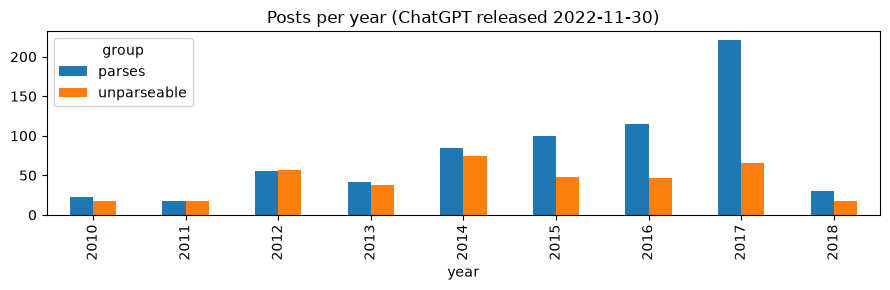

In [8]:
# %% 5. Year by site and group; posts created or edited after ChatGPT.
CHATGPT = pd.Timestamp("2022-11-30")
display(pd.crosstab(d["year"], [d["group"], d["site"]], margins=True))

d["after_chatgpt"] = np.select(
    [d["created"] >= CHATGPT, d["edited"] >= CHATGPT, d["created"].isna()],
    ["created after", "edited after", "no date"], "before")
display(pd.crosstab([d["group"], d["site"]], d["after_chatgpt"], margins=True))

fig, ax = plt.subplots(figsize=(9, 3))
pd.crosstab(d["year"].astype("Int64"), d["group"]).plot.bar(ax=ax)
ax.set_title("Posts per year (ChatGPT released 2022-11-30)"); plt.tight_layout(); plt.show()

**Read:** how many main-set Human Samples were created / edited after 2022-11-30? Drop them, keep them,
or report them as their own Human split? Does the unparseable group skew older (Python 2), so that
"syntax errors" and "age" are confounded?

## 6. Formatting signals that could leak the label

LLM output has LF line endings, spaces, and ASCII. The `atc` and `whodunit` docstrings both name CRLF line endings
in human code as a label leak in their papers' data. Any of these in Human code is a free signal for a Detector.

In [9]:
# %% 6. Formatting flags by group x site x Post type (share of rows).
c = d["code"]
flags = pd.DataFrame({
    "crlf": c.str.contains("\r\n", regex=False),
    "tab_indent": c.str.contains(r"^\t", regex=True, flags=re.M),
    "non_ascii": c.map(lambda s: not s.isascii()),
    "trailing_ws": c.str.contains(r"[ \t]+$", regex=True, flags=re.M),
    "has_comment": c.str.contains(r"#", regex=False),
    "has_docstring": c.str.contains('"""|\'\'\'', regex=True),
    "has_def": c.str.contains(r"^\s*def ", regex=True, flags=re.M),
    "has_class": c.str.contains(r"^\s*class ", regex=True, flags=re.M),
    "has_main_guard": c.str.contains("__main__", regex=False),
})
display(pd.concat([d[["group", "site", "post_type"]], flags], axis=1)
          .groupby(["group", "site", "post_type"]).mean().round(3))

crlf  tab_indent  non_ascii  trailing_ws  has_comment  has_docstring  has_def  has_class  has_main_guard
group       site          post_type                                                                                                          
parses      codereview    answer      0.0         0.0      0.020        0.136        0.435          0.327    0.850      0.190           0.136
                          question    0.0         0.0      0.014        0.241        0.559          0.290    0.855      0.262           0.152
            github        answer      0.0         0.0      0.021        0.021        1.000          0.646    1.000      1.000           0.021
            stackoverflow answer      0.0         0.0      0.015        0.220        0.550          0.205    0.590      0.225           0.100
                          question    0.0         0.0      0.000        0.184        0.469          0.136    0.524      0.190           0.095
unparseable codereview    answer      0.0         0.0      0.034        0.153        0.492          0.169    0.797      0.153           0.169
                          question    0.0         0.0      0.033        0.377        0.754          0.246    0.770      0.180           0.230
            github        answer      0.0         0.0      0.024        0.000        1.000          0.476    1.000      1.000           0.952
            stackoverflow answer      0.0         0.0      0.028        0.266        0.495          0.101    0.358      0.165           0.110
                          question    0.0         0.0      0.027        0.292        0.442          0.044    0.389      0.159           0.115

In [10]:
# %% 6b. Most imported top-level modules in the main set.
IMPORT = re.compile(r"^\s*(?:from\s+([\w]+)|import\s+([\w]+))", re.M)
mods = kept["code"].map(lambda s: {a or b for a, b in IMPORT.findall(s)}).explode().dropna()
display(mods.value_counts().head(20).to_frame("posts"))
print("main set with no import at all:", (kept["code"].map(lambda s: not IMPORT.search(s))).sum())

,posts
code,
numpy,59
matplotlib,36
os,33
sys,31
pandas,28
random,28
itertools,26
collections,21
time,19


main set with no import at all: 324


**Read:** any flag far from 0 that LLM code will not have (CRLF especially)? It would be worth a Formatter-check
style note, or stripping CRLF in the Problems conversion (separate ticket).

## 7. Duplicates and independence

Samples that share a statement, code or author are not independent, and a duplicated statement gives the
Generators the same Prompt twice.

In [11]:
# %% 7. Duplicates.
d["statement"] = d["question_title"] + "\n\n" + d["question_text"]   # as modules/problems.py builds it
k = d[d["parses"]]
print("main set: duplicate statements:", k["statement"].duplicated(keep=False).sum(),
      "| duplicate code:", k["code"].duplicated(keep=False).sum(),
      "| same (site, question_id) twice:", k.duplicated(["site", "question_id"], keep=False).sum())
print("main set: empty question_text (title-only statement):", (k["question_text"].str.strip() == "").sum())
print("main set: same title on different sites:",
      k.groupby("question_title")["site"].nunique().gt(1).sum())

dup_q = k[k.duplicated(["site", "question_id"], keep=False)].sort_values(["site", "question_id"])
display(dup_q[["sample_id", "site", "question_id", "post_type", "code_lines", "question_title"]].head(12))

main set: duplicate statements: 0 | duplicate code: 0 | same (site, question_id) twice: 0
main set: empty question_text (title-only statement): 0
main set: same title on different sites: 0


,sample_id,site,question_id,post_type,code_lines,question_title


In [12]:
# %% 7b. Author concentration (one prolific author = one style counted many times).
a = k.loc[k["author"] != "", "author"].value_counts()
print(f"main set: {a.size} distinct authors for {len(k)} rows; top 10 hold {a.head(10).sum()} rows")
display(a.head(10).to_frame("rows"))

main set: 530 distinct authors for 687 rows; top 10 hold 131 rows


,rows
author,
kamyu104,48
Gareth Rees,20
alecxe,13
200_success,13
Peilonrayz,10
301_Moved_Permanently,7
Stephen Rauch,6
Caridorc,6
unutbu,4


**Read:** do question+answer pairs from one post exist (same statement, two Human Samples)? Keep both, or
one per question? Does any author dominate?

## 8. Statement length, post score, tags, license

In [13]:
# %% 8. Other columns.
k = d[d["parses"]].assign(statement_chars=lambda t: t["statement"].str.len())
display(k.groupby(["site", "post_type"])[["statement_chars", "post_score"]].describe().round(0).T)
tags = k["tags"].str.split(";").explode().str.strip()
display(tags[tags != ""].value_counts().head(20).to_frame("posts"))
display(d.groupby("group")["license"].value_counts().unstack(0).fillna(0).astype(int))

site                  codereview           github stackoverflow         
post_type                 answer question  answer        answer question
statement_chars count      147.0    145.0    48.0         200.0    147.0
                mean       773.0    826.0   223.0         707.0    743.0
                std        462.0    595.0   225.0         535.0    442.0
                min        305.0    302.0    76.0         285.0    283.0
                25%        458.0    466.0    96.0         431.0    460.0
                50%        653.0    635.0   115.0         570.0    593.0
                75%        884.0    920.0   282.0         745.0    910.0
                max       2941.0   4074.0  1337.0        4134.0   3113.0
post_score      count      147.0    145.0     0.0         200.0    147.0
                mean         5.0      6.0     NaN          67.0     99.0
                std          4.0      4.0     NaN          97.0     87.0
                min          1.0      1.0     NaN           1.0     30.0
                25%          2.0      4.0     NaN          14.0     54.0
                50%          4.0      5.0     NaN          34.0     74.0
                75%          6.0      7.0     NaN          77.0    117.0
                max         32.0     28.0     NaN         730.0    592.0

,posts
tags,
python,639
python-3.x,132
performance,54
pandas,42
beginner,41
numpy,37
algorithm,36
matplotlib,31
django,30


group,parses,unparseable
license,,
,4,6
CC BY-SA 2.5,13,13
CC BY-SA 3.0,613,315
CC BY-SA 4.0,9,8
MIT,48,42


**Read:** very short statements (Prompts that under-specify the task)? Licenses all compatible with
redistributing the Samples?

## 9. Sample size

The number of Problems N drives (a) Generator API cost and (b) how precise each Result is.

**Cost.** Fill in the Generators and prices you plan for the full run (`config.toml` lists a placeholder one).
Tokens are estimated from text length (~4 chars per token). Output tokens use the Human code length times a
factor, since LLM answers come with prose and fuller code. Edit the factor if you have real Generate output.

In [14]:
# %% 9. Cost per N. EDIT these inputs.
GENERATORS = {                # name: (USD per 1M input tokens, USD per 1M output tokens)
    "gen-a": (0.15, 0.60),
    "gen-b": (3.00, 15.00),
}
PROMPT_FILES = 2              # "direct" + "style"
TEMPLATE_TOKENS = 150         # Prompt Template text around the statement (check inputs/templates)
OUTPUT_FACTOR = 3.0           # LLM answer tokens / Human code tokens
LLM_JUDGE = (0.25, 2.00)      # judge price; set None to skip. Scores every Sample incl. Formatted copies
EDIT_COUNTS = 2               # Human-fixed Samples per Direct Sample (e.g. Edit counts 2 and 5)

k = d[d["parses"]]
in_tok = k["statement"].str.len().mean() / 4 + TEMPLATE_TOKENS
out_tok = k["code"].str.len().mean() / 4 * OUTPUT_FACTOR
print(f"mean tokens per call: in {in_tok:.0f}, out {out_tok:.0f}")

rows = []
for n in (100, 200, 300, 400, 500, 687):
    calls = n * PROMPT_FILES
    gen_usd = sum(calls * (in_tok * pi + out_tok * po) / 1e6 for pi, po in GENERATORS.values())
    llm = n * len(GENERATORS) * (PROMPT_FILES + EDIT_COUNTS)   # Direct, Style-prompted, Human-fixed
    samples = (n + llm) * 2                                    # every Sample also gets a Formatted copy
    judge_usd = 0 if LLM_JUDGE is None else samples * 3 * (out_tok / OUTPUT_FACTOR * LLM_JUDGE[0] + 50 * LLM_JUDGE[1]) / 1e6
    rows.append(dict(N=n, generate_calls=calls * len(GENERATORS), samples_scored=samples,
                     generate_usd=round(gen_usd, 2), judge_usd=round(judge_usd, 2)))
display(pd.DataFrame(rows).set_index("N"))

mean tokens per call: in 330, out 721


,generate_calls,samples_scored,generate_usd,judge_usd
N,,,,
100,400,1800,2.46,0.86
200,800,3600,4.91,1.73
300,1200,5400,7.37,2.59
400,1600,7200,9.83,3.46
500,2000,9000,12.28,4.32
687,2748,12366,16.88,5.94


**Precision.** A miss rate per Generator per Category is a share of N Samples. Its 95% interval half-width
is about 1.96 * sqrt(p(1-p)/N). The Outdated test compares that against the paper's miss rate, so the
half-width must be smaller than the gaps you want to see. Human splits (one site, one Post type) have fewer
Samples: their FPR is noisier still.

In [15]:
# %% 9b. 95% half-width (percentage points) of a rate p measured on N Samples.
ps = (0.02, 0.05, 0.10, 0.25, 0.50)
ns = (50, 100, 200, 300, 400, 500, 687)
hw = pd.DataFrame({f"p={p}": [100 * 1.96 * np.sqrt(p * (1 - p) / n) for n in ns] for p in ps}, index=ns).round(1)
hw.index.name = "N"
display(hw)
print("Smallest Human splits in the main set (their FPR is measured on this many):")
display(pd.crosstab(k["site"], k["post_type"]))

,p=0.02,p=0.05,p=0.1,p=0.25,p=0.5
N,,,,,
50,3.9,6.0,8.3,12.0,13.9
100,2.7,4.3,5.9,8.5,9.8
200,1.9,3.0,4.2,6.0,6.9
300,1.6,2.5,3.4,4.9,5.7
400,1.4,2.1,2.9,4.2,4.9
500,1.2,1.9,2.6,3.8,4.4
687,1.0,1.6,2.2,3.2,3.7


Smallest Human splits in the main set (their FPR is measured on this many):


post_type,answer,question
site,,
codereview,147,145
github,48,0
stackoverflow,200,147


**Subset rule, if N < 687.** Proposed: stratified random sample by site x Post type, proportional to the
counts above, fixed seed, so every Human split keeps its share. Implementing it is a change to
`modules/problems.py` (separate ticket).

In [16]:
# %% 9c. Preview a stratified subset (does not write anything).
N, SEED = 300, 0
k = d[d["parses"]]
sub = k.groupby(["site", "post_type"]).sample(frac=N / len(k), random_state=SEED)   # rounds per stratum
print(len(sub), "Problems")
display(pd.concat({"all": k.groupby(["site", "post_type"]).size(),
                   "subset": sub.groupby(["site", "post_type"]).size()}, axis=1))
display(pd.concat({"all": k["code_lines"].describe(), "subset": sub["code_lines"].describe()}, axis=1).round(1))

299 Problems


all  subset
site          post_type             
codereview    answer     147      64
              question   145      63
github        answer      48      21
stackoverflow answer     200      87
              question   147      64

,all,subset
count,687.0,299.0
mean,30.7,31.1
std,22.1,22.6
min,10.0,10.0
25%,15.0,15.0
50%,22.0,23.0
75%,38.0,36.0
max,126.0,121.0


**Read:** cost and half-width at each N; which N gives a half-width you can live with at a cost you can pay?

## 10. Unparseable rows as a separate Human group

The group needs **no generation**: it is Human Samples only. The measure is the FPR on unparseable Human code
next to the FPR on parseable Human code, per Detector. The gap shows how much syntax errors alone move a
Detector. Cost is scoring only (384 Samples, plus `llm_judge` API calls).

Which Detectors can read it (from the Detector docstrings):

| Detector | Input | Reads unparseable code? |
|---|---|---|
| `random_baseline` | none | yes (control) |
| `xgb_tfidf` | tiktoken token ids | yes |
| `droiddetect` | ModernBERT tokens | yes |
| `atc` | CodeLlama logits | yes |
| `llm_judge` | raw code in a Prompt | yes |
| `whodunit` | AST / radon stylometry | **no** (its docstring scores code it cannot read as 0.5) |

The group gets no Formatted copies (black needs parseable code) and no Human-fixed Samples (those come from
Direct Samples). The confound to check below: if unparseable code is older, shorter, or from other sites than
parseable code, an FPR gap is not "syntax errors alone".

In [17]:
# %% 10. Parseable vs unparseable side by side.
cmp = pd.DataFrame({
    g: {"rows": len(x),
        "median lines": x["code_lines"].median(),
        "median year": x["year"].median(),
        "created after ChatGPT": (x["created"] >= CHATGPT).mean().round(3),
        "share answer": (x["post_type"] == "answer").mean().round(3),
        **{f"share {s}": (x["site"] == s).mean().round(3) for s in sorted(d["site"].unique())},
        "share CRLF": x["code"].str.contains("\r\n", regex=False).mean().round(3)}
    for g, x in d.groupby("group")})
display(cmp)
display(pd.crosstab(d["fail_bucket"], d["post_type"]).drop(index="parses on this Python", errors="ignore"))

,parses,unparseable
rows,687.000,384.000
median lines,22.000,24.000
median year,2016.000,2014.000
created after ChatGPT,0.000,0.000
share answer,0.575,0.547
share codereview,0.425,0.312
share github,0.070,0.109
share stackoverflow,0.505,0.578
share CRLF,0.000,0.000


post_type,answer,question
fail_bucket,,
cut off / unclosed,4,0
elided lines (...),7,1
indentation,22,18
other,51,43
pasted REPL/shell,11,7
python2,113,99


**Read:** is the group comparable to the main set apart from parsing? If not, match it (e.g. compare against
parseable rows of the same site / Post type / era) before reading the FPR gap as a syntax effect.

## 11. Decisions

Recorded in `docs/adr/0003-first-run-problems.md`.

- **Sample size N:** all 687 parseable Problems. Cost is small (~$17 at the placeholder prices) and the miss-rate half-width is at most 3.7 points (section 9).
- **Subset rule:** none. The 9c cell stays as a fallback in case real Generator prices are far higher.
- **Parse filter:** the delivered `code_parses` column, not re-checked. 8 rows marked False parse on 3.13 (more on 3.14); they stay out.
- **Posts after 2022-11-30:** none exist (2010-2018), so no rule. Memorization is the age risk instead: #33.
- **Length / CRLF:** no rule. The minimum is already 10 lines, and there is no CRLF.
- **GitHub:** kept. All 48 rows are one author (`kamyu104`) and LeetCode-style with short statements, so its Human split is reported with that caveat.
- **Unparseable group:** all 384 rows scored as a separate Human group by `random_baseline`, `xgb_tfidf`, `droiddetect`, `atc` and `llm_judge` (not `whodunit`), in their own tables. FPR is shown pooled, per failure type (Python 2 headline), and against parseable rows within each site x Post type: #46.
- **Follow-up tickets:** #33 (memorization), #46 (unparseable group).